# S3a — Conditional VAE (CVAE)

**Goal:** learn $p(x \mid y)$, dermoscopy images $x$ given the class $y$, with a conditional VAE (AE/VAE course, slides 11–21).

| Part | Choice | Course |
|---|---|---|
| Encoder $q(z \mid x, y)$ | image + one-hot class maps → strided convs → $\mu$, $\log\sigma^2$ (two heads) | slides 16, 21 |
| Reparameterisation | $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$ | slide 15 |
| Decoder $p(x \mid z, y)$ | $[z, \text{embedding}(y)]$ → DCGAN generator → 3 × 64 × 64, `tanh` (**same network as the cGAN generator**) | slides 21 (VAE), 19–20 (GAN) |
| Loss | $-\text{ELBO}$ = reconstruction (MSE, Gaussian decoder) $+\ \beta \cdot$ KL, with KL warm-up | slides 12, 20 |
| Generation | choose $y$, draw $z \sim \mathcal{N}(0, I)$, decode $[z, y]$ | slide 21 |

**β experiment (β-VAE, slide 20):** we train β = 0.5, 1 and 2. Expected: β < 1 → sharper reconstructions, β > 1 → smoother latent space but blurrier images. **β = 1 is the main model** used in the next steps.

**Settings:** `configs/cvae.yaml` — 15 epochs, Adam 1e-3, z of size 64, sqrt-balanced sampler (rare classes seen more often, without repeating them as much as full oversampling).

> Use a GPU (Colab). `QUICK = True` trains only β = 1 for 10 epochs.

In [5]:
# --- Setup: works locally (.venv) and with the VS Code Colab kernel, WITHOUT git ---
# The project code (src/, configs/) travels inside this cell. After changing code on the laptop, run:
#     python -m src.sync_code notebooks/03a_cvae.ipynb notebooks/03b_cgan.ipynb
# then run this notebook again.
CODE_ZIP = "..."

import os, sys, io, base64, zipfile, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
if IN_COLAB:
    root = Path("/content/mini_project")
    root.mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile(io.BytesIO(base64.b64decode(CODE_ZIP))).extractall(root)   # laptop code -> Colab
    os.chdir(root)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist", "pyyaml"], check=True)
    for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
        del sys.modules[name]           # forget any older version of src already loaded in this kernel
elif Path.cwd().name == "notebooks":
    os.chdir("..")                      # local run: go to the repository root

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print("Project root:", Path.cwd())

Project root: /content/mini_project


In [6]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from src.data import load_split, to_tensor, sample_per_class, NUM_CLASSES, SHORT_NAMES
from src.train_gen import train_cvae, generate, class_diversity
from src.viz import plot_grid, plot_class_grid
from src.utils import (load_config, get_device, ensure_dirs, lerp, save_half, export_results,
                       RESULTS_DIR, CKPT_DIR)

QUICK = False          # True = shorter run: only beta = 1, 10 epochs

cfg = load_config("cvae")
if QUICK:
    cfg["train"].update(epochs=10, betas=[1.0])
MAIN_BETA = 1.0
N = cfg["sampling"]["n_per_class"]
Z_DIM = cfg["model"]["z_dim"]
ensure_dirs()
device = get_device()
print("device:", device, "| train config:", cfg["train"])

train_x, train_y = load_split("train", cfg["data"]["size"])
val_x, val_y = load_split("val", cfg["data"]["size"])
print("train", train_x.shape, "| val", val_x.shape)

device: cuda | train config: {'epochs': 15, 'lr': 0.001, 'kl_warmup_epochs': 5, 'betas': [0.5, 1.0, 2.0], 'class_power': 0.5, 'seed': 0}


100%|██████████| 100M/100M [00:04<00:00, 22.8MB/s] 


train (7007, 64, 64, 3) | val (1003, 64, 64, 3)


## 1. Training (one CVAE per β)

In [7]:
runs = {}
for beta in cfg["train"]["betas"]:
    print(f"\n=== CVAE, beta = {beta} ===")
    model, history, grids = train_cvae(train_x, train_y, cfg, beta=beta, seed=cfg["train"]["seed"], device=device)
    torch.save(model.state_dict(), CKPT_DIR / f"cvae_beta{beta}.pt")
    runs[beta] = {"model": model, "history": history, "grids": grids}

model = runs[MAIN_BETA]["model"]
save_half(model.state_dict(), CKPT_DIR / "cvae.pt")          # main model (beta = 1), used in S4
with open(RESULTS_DIR / "s3_cvae_history.json", "w") as f:
    json.dump({str(b): r["history"] for b, r in runs.items()}, f, indent=1)
print("Main model saved: checkpoints/cvae.pt")


=== CVAE, beta = 0.5 ===
[CVAE beta=0.5] epoch  1/15 | beta_t 0.10 | recon  1289.7 | KL 6984517358.4 | 5s
[CVAE beta=0.5] epoch  2/15 | beta_t 0.20 | recon   634.4 | KL  156.2 | 3s
[CVAE beta=0.5] epoch  3/15 | beta_t 0.30 | recon   435.5 | KL  108.2 | 3s
[CVAE beta=0.5] epoch  4/15 | beta_t 0.40 | recon   334.6 | KL   88.3 | 3s
[CVAE beta=0.5] epoch  5/15 | beta_t 0.50 | recon   282.1 | KL   83.0 | 3s
[CVAE beta=0.5] epoch  6/15 | beta_t 0.50 | recon   261.1 | KL   76.4 | 3s
[CVAE beta=0.5] epoch  7/15 | beta_t 0.50 | recon   241.5 | KL   73.0 | 3s
[CVAE beta=0.5] epoch  8/15 | beta_t 0.50 | recon   221.8 | KL   68.7 | 3s
[CVAE beta=0.5] epoch  9/15 | beta_t 0.50 | recon   206.2 | KL   66.7 | 3s
[CVAE beta=0.5] epoch 10/15 | beta_t 0.50 | recon   208.8 | KL   68.0 | 3s
[CVAE beta=0.5] epoch 11/15 | beta_t 0.50 | recon   203.9 | KL   68.6 | 3s
[CVAE beta=0.5] epoch 12/15 | beta_t 0.50 | recon   197.4 | KL   67.3 | 3s
[CVAE beta=0.5] epoch 13/15 | beta_t 0.50 | recon   198.7 | KL   67.

## 2. Loss curves

The two ELBO terms compete (slide 12): reconstruction pulls towards faithful images, KL pulls the codes towards $\mathcal{N}(0, I)$. During the first 5 epochs β grows from 0 (KL warm-up), so the KL first increases, then is pushed down.

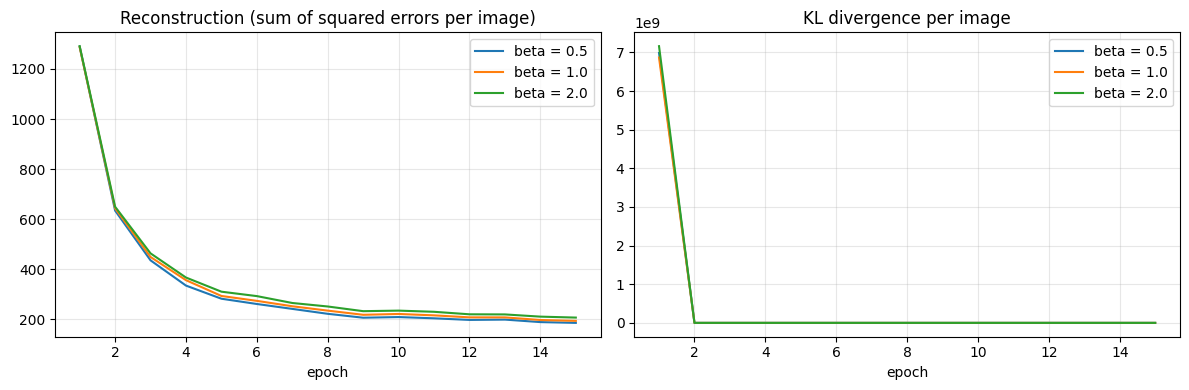

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for beta, r in runs.items():
    ep = [h["epoch"] for h in r["history"]]
    axes[0].plot(ep, [h["recon"] for h in r["history"]], label=f"beta = {beta}")
    axes[1].plot(ep, [h["kl"] for h in r["history"]], label=f"beta = {beta}")
axes[0].set_title("Reconstruction (sum of squared errors per image)")
axes[1].set_title("KL divergence per image")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cvae_losses.png", dpi=100, bbox_inches="tight")
plt.show()

## 3. Real vs synthetic images (β = 1)

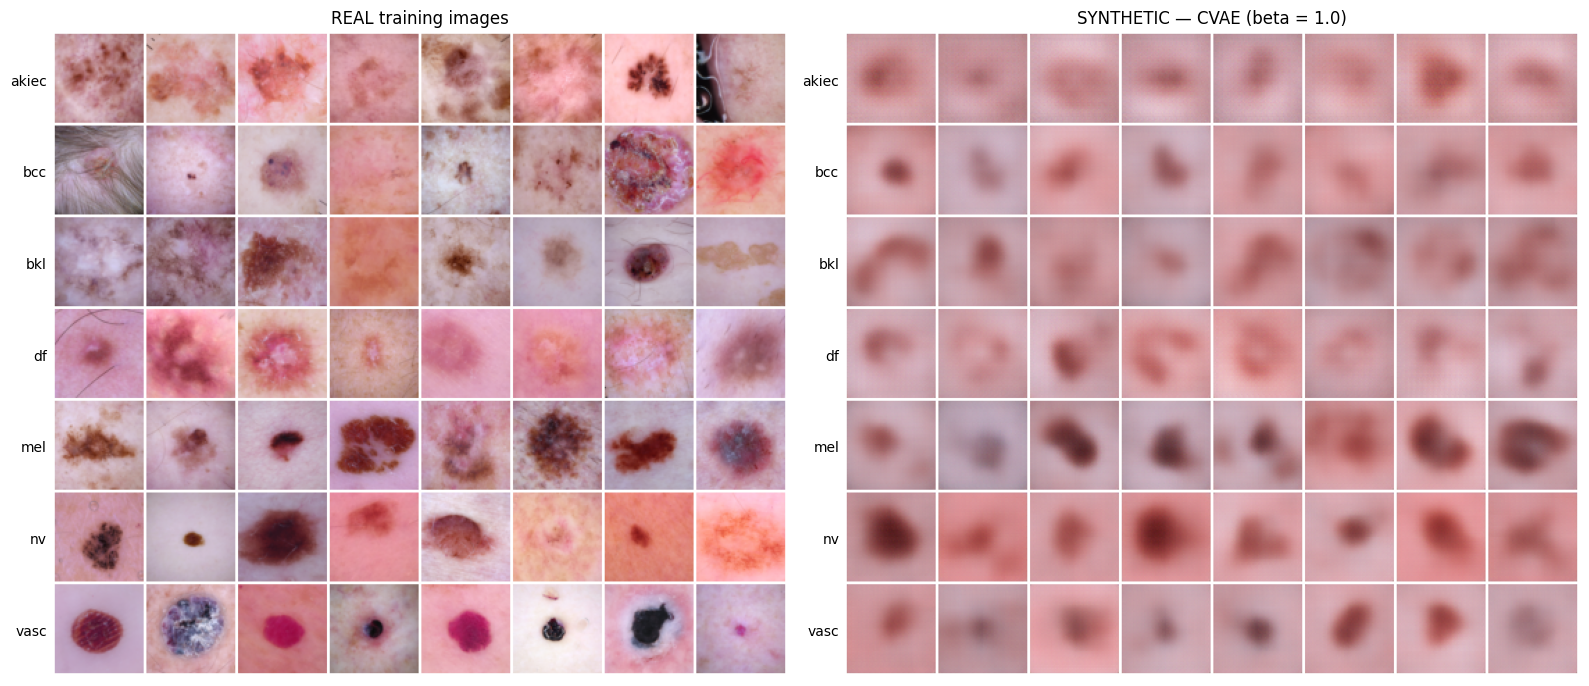

In [9]:
real, _ = sample_per_class(train_x, train_y, N, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
plot_class_grid(real, N, ax=axes[0], title="REAL training images")
plot_class_grid(runs[MAIN_BETA]["grids"][-1], N, ax=axes[1], title=f"SYNTHETIC — CVAE (beta = {MAIN_BETA})")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cvae_samples.png", dpi=100, bbox_inches="tight")
plt.show()

## 4. Evolution during training (same z and classes at every epoch)

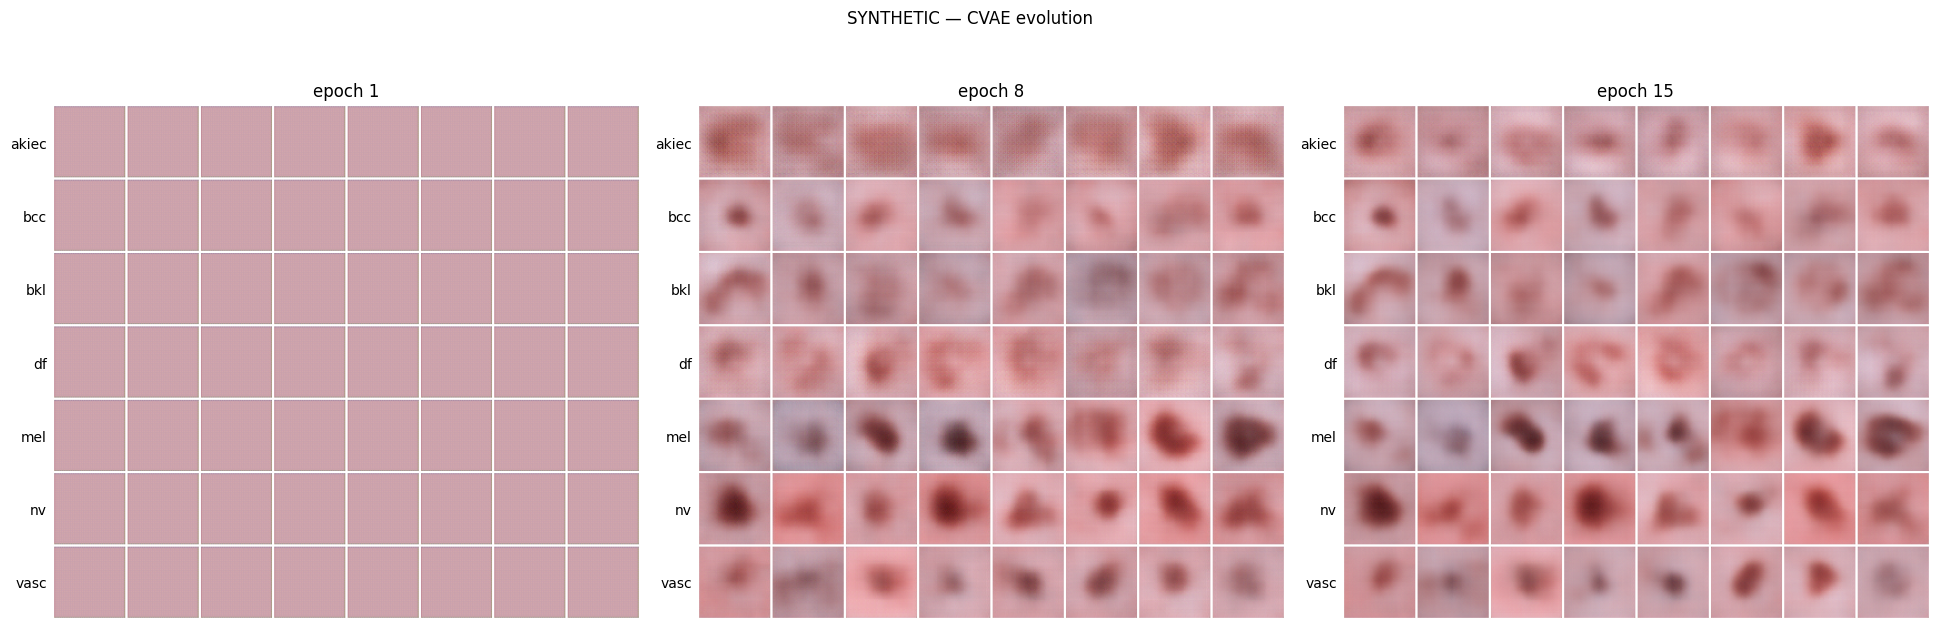

In [10]:
grids = runs[MAIN_BETA]["grids"]
idx = sorted({0, len(grids) // 2, len(grids) - 1})
fig, axes = plt.subplots(1, len(idx), figsize=(6.5 * len(idx), 7))
for ax, i in zip(np.atleast_1d(axes), idx):
    plot_class_grid(grids[i], N, ax=ax, title=f"epoch {i + 1}")
fig.suptitle("SYNTHETIC — CVAE evolution")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cvae_evolution.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Reconstructions and the β experiment

Validation images are encoded ($z = \mu$) and decoded. The table gives, for each β, the final KL, the reconstruction error on the **validation** set (MSE per pixel, pixels in [-1, 1]) and the sample diversity (synthetic / real, averaged over classes).

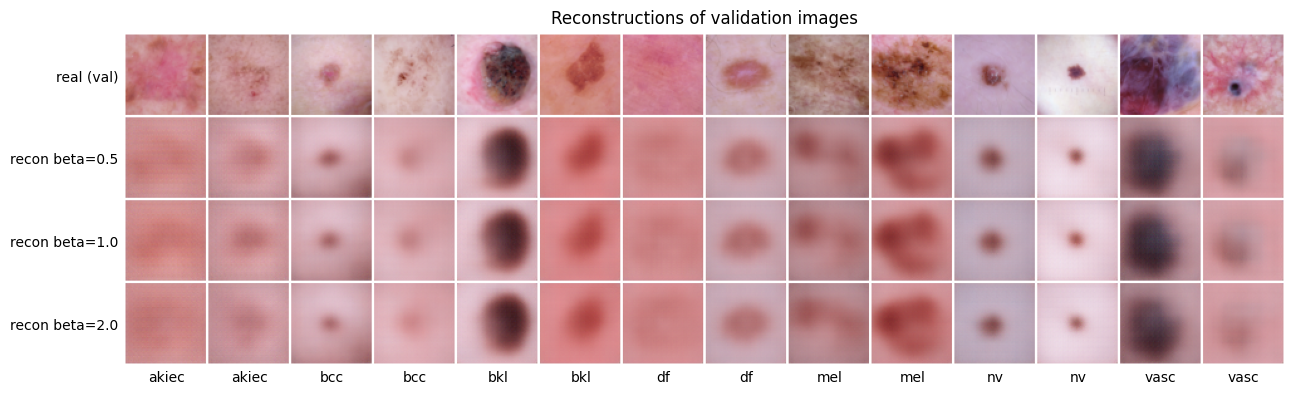

,final KL,val MSE / pixel,diversity ratio (mean)
beta,,,
0.5,64.9,0.0119,0.49
1.0,41.7,0.0123,0.52
2.0,29.1,0.0131,0.57


In [11]:
@torch.no_grad()
def reconstruct(m, x, y):
    m.eval()
    mu, _ = m.encoder(x, y)
    return m.decoder(mu, y)


@torch.no_grad()
def val_mse(m):
    total, count = 0.0, 0
    for i in range(0, len(val_x), 256):
        x = to_tensor(val_x[i:i + 256]).to(device)
        y = torch.as_tensor(val_y[i:i + 256]).to(device)
        total += F.mse_loss(reconstruct(m, x, y), x, reduction="sum").item()
        count += x.numel()
    return total / count


x_show, y_show = sample_per_class(val_x, val_y, 2, seed=0)        # 2 validation images per class
x_show, y_show = x_show.to(device), y_show.to(device)
rows, labels = [x_show.cpu()], ["real (val)"]
table = []
for beta, r in runs.items():
    rows.append(reconstruct(r["model"], x_show, y_show).cpu())
    labels.append(f"recon beta={beta}")
    div = class_diversity(r["model"].decoder, train_x, train_y, device)
    table.append({"beta": beta, "final KL": round(r["history"][-1]["kl"], 1),
                  "val MSE / pixel": round(val_mse(r["model"]), 4),
                  "diversity ratio (mean)": round(div["ratio"].mean(), 2)})

fig, ax = plt.subplots(figsize=(15, 1.3 * len(rows) + 0.5))
plot_grid(torch.cat(rows), len(x_show), ax=ax, row_labels=labels,
          col_labels=[SHORT_NAMES[c] for c in y_show.tolist()], title="Reconstructions of validation images")
fig.savefig(RESULTS_DIR / "s3_cvae_reconstructions.png", dpi=100, bbox_inches="tight")
plt.show()

beta_table = pd.DataFrame(table).set_index("beta")
beta_table.to_csv(RESULTS_DIR / "s3_cvae_beta_table.csv")
beta_table

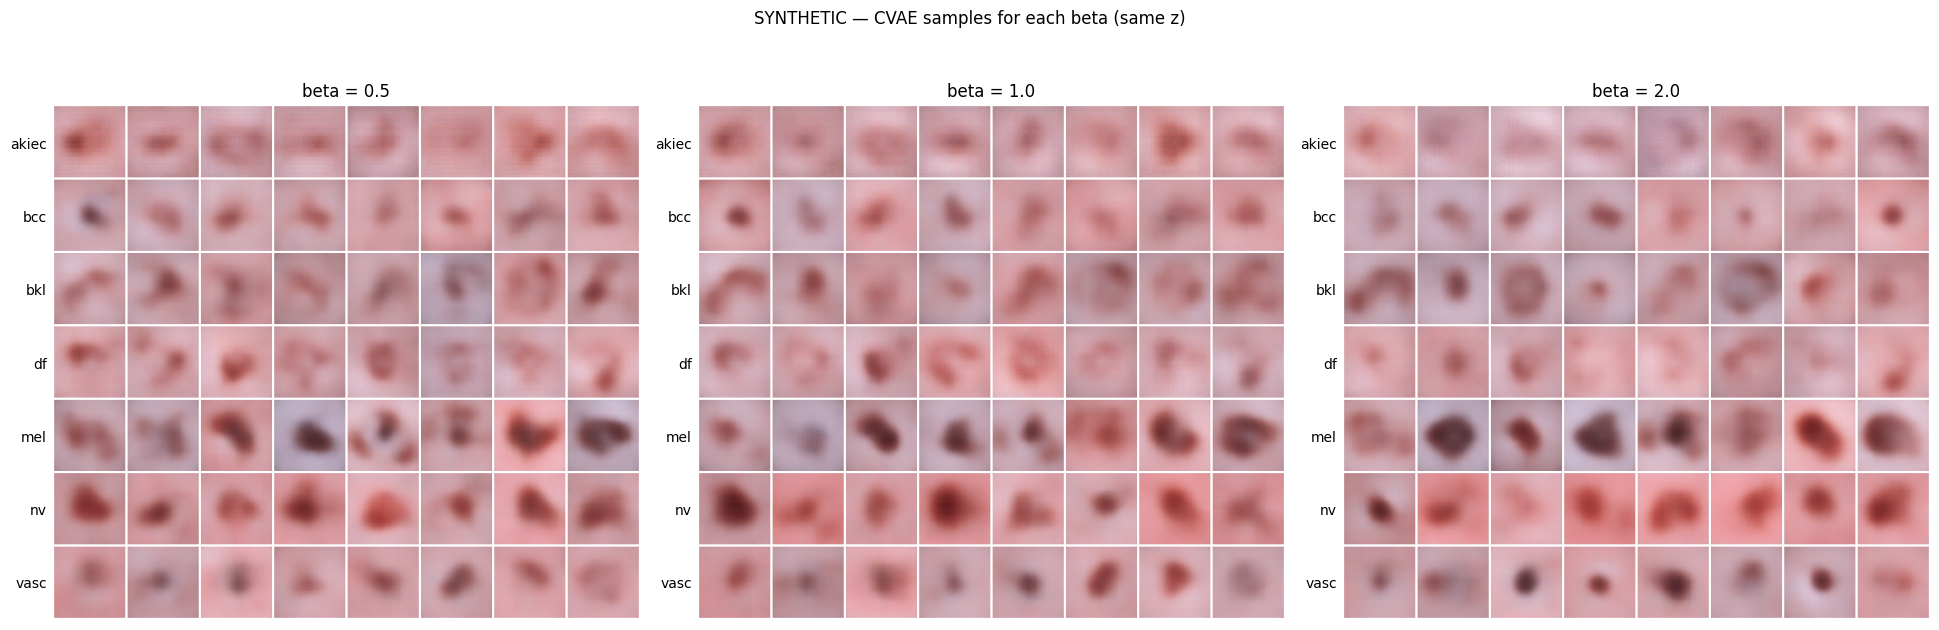

In [12]:
fig, axes = plt.subplots(1, len(runs), figsize=(6.5 * len(runs), 7))
for ax, (beta, r) in zip(np.atleast_1d(axes), runs.items()):
    plot_class_grid(r["grids"][-1], N, ax=ax, title=f"beta = {beta}")
fig.suptitle("SYNTHETIC — CVAE samples for each beta (same z)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s3_cvae_beta_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Diversity per class (β = 1)

Mean pairwise distance between 64 generated images of a class, divided by the same measure on 64 real images. A ratio well below 1 means too little variety.

In [13]:
div_main = class_diversity(model.decoder, train_x, train_y, device)
div_main.to_csv(RESULTS_DIR / "s3_cvae_diversity.csv")
div_main

,real diversity,synthetic diversity,ratio
class,,,
akiec,33.16,16.17,0.49
bcc,32.47,17.95,0.55
bkl,35.41,18.27,0.52
df,33.27,23.77,0.71
mel,46.40,26.21,0.56
nv,40.47,21.33,0.53
vasc,41.25,16.37,0.40


## 7. Does the class really control the image? (class swap)

Each **row** uses the same $z$; each **column** is a different class. If the conditioning works, the lesion type changes along a row while the "style" of the row (size, position, skin tone) stays similar.

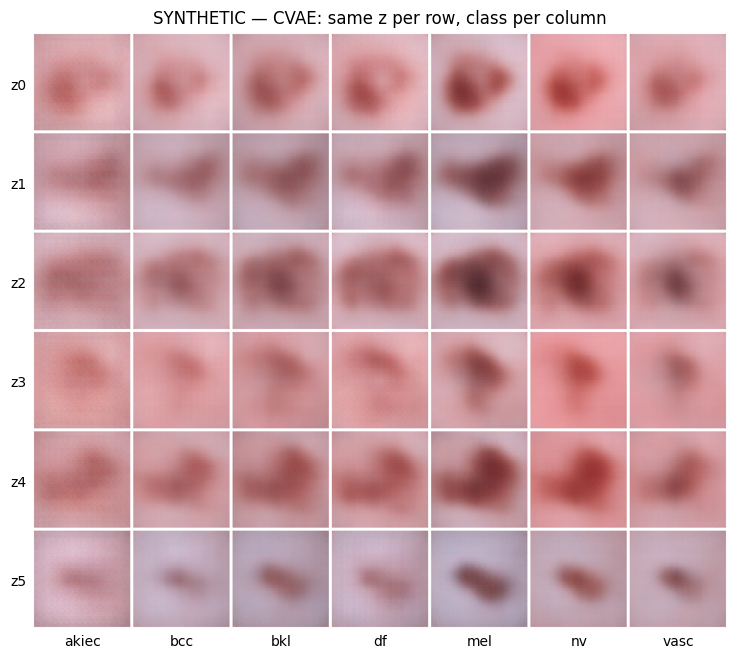

In [14]:
g = torch.Generator().manual_seed(1)
z = torch.randn(6, Z_DIM, generator=g).to(device)
zz = z.repeat_interleave(NUM_CLASSES, dim=0)
yy = torch.arange(NUM_CLASSES).repeat(6).to(device)
imgs = generate(model.decoder, yy, zz).cpu()
fig, ax = plt.subplots(figsize=(9, 8))
plot_grid(imgs, NUM_CLASSES, ax=ax, col_labels=SHORT_NAMES, row_labels=[f"z{i}" for i in range(6)],
          title="SYNTHETIC — CVAE: same z per row, class per column")
fig.savefig(RESULTS_DIR / "s3_cvae_class_swap.png", dpi=100, bbox_inches="tight")
plt.show()

## 8. Latent interpolation

Linear interpolation between two codes $z_0 \to z_1$ with a fixed class (AE/VAE course, slide 9). A smooth morphing means the latent space is continuous (no "holes").

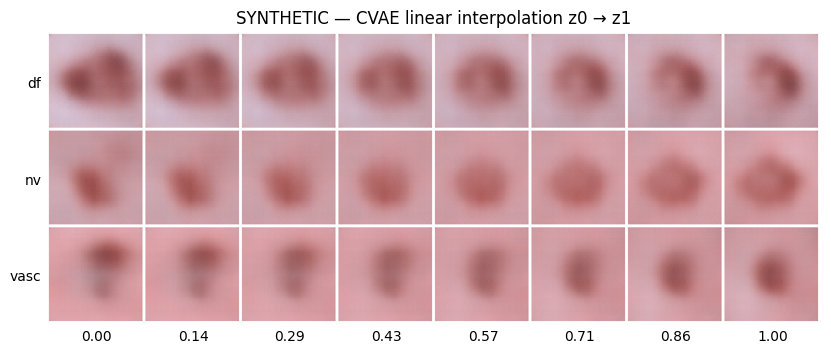

In [15]:
steps = 8
t = torch.linspace(0, 1, steps, device=device).view(-1, 1)
g = torch.Generator().manual_seed(2)
classes = [3, 5, 6]                                   # df, nv, vasc
rows = []
for c in classes:
    z0, z1 = torch.randn(2, Z_DIM, generator=g).to(device).chunk(2)
    rows.append(generate(model.decoder, torch.full((steps,), c, device=device), lerp(z0, z1, t)).cpu())
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_grid(torch.cat(rows), steps, ax=ax, row_labels=[SHORT_NAMES[c] for c in classes],
          col_labels=[f"{v:.2f}" for v in t.flatten().tolist()], title="SYNTHETIC — CVAE linear interpolation z0 → z1")
fig.savefig(RESULTS_DIR / "s3_cvae_interpolation.png", dpi=100, bbox_inches="tight")
plt.show()

## 9. Interpretation (to complete after running)

- **Sharpness (hypothesis H1):** are the samples blurry compared with the real images? The course explains why (slide 19): with an MSE loss the decoder predicts the *average* of the possible images.
- **β experiment:** compare the reconstructions and the samples for β = 0.5 / 1 / 2. Does a smaller β give sharper reconstructions and a larger β blurrier ones? Use the table (val MSE, KL, diversity).
- **Diversity (H2):** are the ratios close to 1 for most classes? What about **df** (only 80 training images)?
- **Class swap:** does the lesion type follow the column (for example red/purple for vasc, dark brown for mel/nv)?
- **Interpolation:** is the morphing smooth?

## Conclusion of S3a
- Main model: `checkpoints/cvae.pt` (β = 1, float16). Other β: `checkpoints/cvae_beta*.pt` (not exported).
- Figures and tables: `results/s3_cvae_*`.
- Next: **S3b**, the conditional GAN with the same generator architecture.

## Export the results (Colab only)

On Colab the files are written on Google's machine. This cell zips the figures, the history and the main checkpoint (in float16, to keep it small):
- **browser Colab:** the zip is downloaded automatically (ignore the long text printed below it);
- **VS Code + Colab kernel:** the zip is printed as text. **Save the notebook (Ctrl+S)**, then run locally from the repository root:
  `python -m src.extract_results notebooks\03a_cvae.ipynb`

In [16]:
export_results(sorted(RESULTS_DIR.glob("s3_cvae_*")) + [CKPT_DIR / "cvae.pt"], "s3_cvae_results.zip")

[11958422 bytes extracted locally with src.extract_results: 11 files]
